# Problem 2 — Pocket Rubik's Cube & State-Space Search
**Algorithms and Data Structures — Guided Examination**

Group members: *Diya Sharma, Siddhant Patel, Srikrishna Ravi, Lavanyaa More*

We solve the 2×2×2 Pocket Cube as a shortest-path problem on an implicit graph with 3,674,160 vertices,
and climb the 5-stage ladder:

| Stage | State representation | Search |
|---|---|---|
| V1 | 24-sticker mutable array | depth-limited DFS, no visited set |
| V2 | immutable tuple `(perm, orient)` | BFS with FIFO queue + hash map |
| V3 | tuple | BFS with redundant-move pruning |
| V4 | tuple | bidirectional BFS (meet in the middle) |
| V5 | tuple | IDA* with admissible corner heuristic (+ optional pattern tables) |

## 0. Cube model
The moves R, R′ and U are exactly as given on the problem sheet. U′ is the inverse cycle of U; F and F′ act on the front face {0, 1, 5, 4} with the same twist pattern (+1, +2, +1, +2) as R.

In [ ]:
import random 
from collections import deque # which allows for fast appends and pops from both ends (BFS)
import time, math 

SOLVED = ((0, 1, 2, 3, 4, 5, 6), (0, 0, 0, 0, 0, 0, 0))

# Rotations and twists for each move, in the form of (target, source, orientation_change)
_R  = ((1, 2, 6, 5), (5, 1, 2, 6), (1, 2, 1, 2))
_Ri = ((1, 2, 6, 5), (2, 6, 5, 1), (1, 2, 1, 2))
_U  = ((0, 3, 2, 1), (1, 0, 3, 2), (0, 0, 0, 0))
# Derived: U' is the inverse cycle of U
_Ui = ((0, 3, 2, 1), (3, 2, 1, 0), (0, 0, 0, 0))
# Derived: F on front face {0,1,5,4}, same twist pattern as R
_F  = ((0, 1, 5, 4), (4, 0, 1, 5), (1, 2, 1, 2))
_Fi = ((0, 1, 5, 4), (1, 5, 4, 0), (1, 2, 1, 2))

MOVES = {"U": _U, "U'": _Ui, "R": _R, "R'": _Ri, "F": _F, "F'": _Fi}
INVERSE = {"U": "U'", "U'": "U", "R": "R'", "R'": "R", "F": "F'", "F'": "F"}


def apply_move(s, m):
    perm, orient = s
    p, o = list(perm), list(orient) 
    tg, src, dl = MOVES[m] # tg = target, src = source, dl = delta (orientation change)
    for t, sr, d in zip(tg, src, dl):
        p[t] = perm[sr]
        o[t] = (orient[sr] + d) % 3 
    return (tuple(p), tuple(o))

### Sanity check: every move is undone by its inverse, and the whole graph has 3,674,160 states

In [ ]:
for m in MOVES:
    assert apply_move(apply_move(SOLVED, m), INVERSE[m]) == SOLVED 
print("all 6 inverses OK")

# Full BFS from the solved state (about 60s in Python): confirms the move set and gives God's number.
RUN_FULL_BFS = True
if RUN_FULL_BFS:  
    t0 = time.perf_counter() 
    dist_all = {SOLVED: 0} ; q = deque([SOLVED]) # waiting list of states to explore
    while q: # keeps going until something is waiting in the queue
        s = q.popleft()
        for m in MOVES:
            t = apply_move(s, m)
            if t not in dist_all:
                dist_all[t] = dist_all[s] + 1; q.append(t)
    from collections import Counter 
    layer = Counter(dist_all.values()) # counts how many states are at each depth
    print(f"reachable states: {len(dist_all):,}  (7! * 3^6 = {math.factorial(7) * 3**6:,})")
    print("states per depth:", [layer[d] for d in sorted(layer)]) 
    print("God's number (quarter-turn metric):", max(layer), f"  [{time.perf_counter()-t0:.1f} s]") 

all 6 inverses OK
reachable states: 3,674,160  (7! * 3^6 = 3,674,160)
states per depth: [1, 6, 27, 120, 534, 2256, 8969, 33058, 114149, 360508, 930588, 1350852, 782536, 90280, 276]
God's number (quarter-turn metric): 14   [62.8 s]


## Part A in code — Q1 trace and Q2 twist invariant

In [20]:
s0 = SOLVED
s1 = apply_move(s0, "R") 
s2 = apply_move(s1, "U")
s3 = apply_move(s2, "R'")
for name, s in [("s1", s1), ("s2", s2), ("s3", s3)]:
    print(f"{name}: perm={s[0]}  orient={s[1]}  sum(orient)={sum(s[1])}  (mod 3 = {sum(s[1]) % 3})")
print("R then R' returns s0:", apply_move(s1, "R'") == s0)

s1: perm=(0, 5, 1, 3, 4, 6, 2)  orient=(0, 1, 2, 0, 0, 2, 1)  sum(orient)=6  (mod 3 = 0)
s2: perm=(5, 1, 3, 0, 4, 6, 2)  orient=(1, 2, 0, 0, 0, 2, 1)  sum(orient)=6  (mod 3 = 0)
s3: perm=(5, 3, 2, 0, 4, 1, 6)  orient=(1, 1, 0, 0, 0, 1, 0)  sum(orient)=3  (mod 3 = 0)
R then R' returns s0: True


In [21]:
def twist_invariant_ok(s):
    """Every move adds 0 or 6 to the orientation sum, so reachable states have sum % 3 == 0."""
    return sum(s[1]) % 3 == 0

dropped = ((0, 1, 2, 3, 4, 5, 6), (1, 0, 0, 0, 0, 0, 0))   # one corner snapped back twisted +1
print("solved state solvable?  ", twist_invariant_ok(SOLVED))
print("dropped cube solvable?  ", twist_invariant_ok(dropped))
if RUN_FULL_BFS:
    print("dropped state in the BFS graph of SOLVED?", dropped in dist_all)

solved state solvable?   True
dropped cube solvable?   False
dropped state in the BFS graph of SOLVED? False


## Stage 1 — 24-sticker array + unpruned depth-limited DFS

In [ ]:
MOVE_NAMES = list(MOVES)              # ["U","U'","R","R'","F","F'"]
FACE = {m: m[0] for m in MOVE_NAMES}  # {"U":"U","U'":"U","R":"R","R'":"R","F":"F","F'":"F"}

# 24-sticker array: stickers[3*slot + j]. Slot 7 (DBL) never moves.
# A cubie c in slot t with orientation o shows its facelet (j - o) % 3 at position j.[8 corn pieces, 3 stickers each = 24 stickers]
SLOT_NAMES = ["UFL", "UFR", "UBR", "UBL", "DFL", "DFR", "DBR", "DBL"]
SOLVED_STICKERS = [SLOT_NAMES[t][j] for t in range(8) for j in range(3)]


# sticker_permutation used to update the 24-sticker array for a move, derived from the cubie rule.
def _sticker_perm(m):
    """new[i] = old[P[i]] for move m, derived from the cubie rule."""
    P = list(range(24)) 
    tg, src, dl = MOVES[m] # target, source, delta (orientation change)
    for t, s, d in zip(tg, src, dl):
        for j in range(3): # 3 stickers per cubie
            P[3 * t + j] = 3 * s + (j - d) % 3
    return P


STICKER_PERMS = {m: _sticker_perm(m) for m in MOVE_NAMES}

# state_to_stickers used to convert a cubie state to a 24-sticker array, for easy comparison of states.
def state_to_stickers(s):
    perm, orient = s
    st = list(SOLVED_STICKERS)
    for t in range(7):
        c, o = perm[t], orient[t]
        for j in range(3):
            st[3 * t + j] = SLOT_NAMES[c][(j - o) % 3]
    return st

# sticker_move used to update a 24-sticker array for a move, derived from the cubie rule. 
def sticker_move(st, m):
    P = STICKER_PERMS[m]
    return [st[P[i]] for i in range(24)]        # fresh mutable list each move


def v1_dfs_unpruned(start, goal, max_depth):
    """Depth-limited DFS, no visited set, no pruning. Returns first path found."""
    start_st, goal_st = state_to_stickers(start), state_to_stickers(goal)
    stats = {"expanded": 0, "generated": 0, "peak_states": 0}
    path = [] # list of moves taken to reach the goal, if found

    def dfs(st, depth):
        stats["expanded"] += 1 
        stats["peak_states"] = max(stats["peak_states"], depth + 1)
        if st == goal_st:
            return True
        if depth == max_depth:
            return False
        for m in MOVE_NAMES:
            stats["generated"] += 1
            path.append(m)
            if dfs(sticker_move(st, m), depth + 1):
                return True
            path.pop()
        return False

    found = dfs(start_st, 0)
    return (list(path) if found else None), stats

In [ ]:
# Stickers and cubie tuples describe the same cube
rng = random.Random(0) 
for _ in range(200):    
    s = SOLVED; st = list(SOLVED_STICKERS)
    for m in rng.choices(MOVE_NAMES, k=10):
        s = apply_move(s, m); st = sticker_move(st, m)
    assert st == state_to_stickers(s)
print("sticker model agrees with tuple model")

# Why Stage 1 fails: on a 2-move scramble, DFS with a cap returns a much longer path
start = apply_move(apply_move(SOLVED, "R"), "U")
print("\nscramble R U  (optimal solution has 2 moves)")
for cap in [2, 3, 4, 5, 6, 7]:
    path, st = v1_dfs_unpruned(start, SOLVED, cap)
    print(f"max_depth={cap}: returned {len(path)} moves {path}  nodes expanded={st['expanded']:,}")

sticker model agrees with tuple model

scramble R U  (optimal solution has 2 moves)
max_depth=2: returned 2 moves ["U'", "R'"]  nodes expanded=13
max_depth=3: returned 2 moves ["U'", "R'"]  nodes expanded=67
max_depth=4: returned 4 moves ['U', 'U', 'U', "R'"]  nodes expanded=8
max_depth=5: returned 4 moves ['U', 'U', 'U', "R'"]  nodes expanded=26
max_depth=6: returned 6 moves ['U', 'U', 'U', 'U', "U'", "R'"]  nodes expanded=17
max_depth=7: returned 6 moves ['U', 'U', 'U', 'U', "U'", "R'"]  nodes expanded=71


## Helpers — path reconstruction and move-pruning rule (used by Stages 3–5)
In the quarter-turn metric a double turn XX costs 2 moves and can be optimal, so we keep it. We forbid X followed by X′ (undoes it), XXX (equals X′), and X′X′ (same state as XX).

In [ ]:
# rec
def reconstruct(parent, s):
    moves = []
    while parent[s] is not None: # stop when we reach the start state (which has no parent)
        prev, m = parent[s]
        moves.append(m)
        s = prev
    return moves[::-1] 

# pruning rules for Stages 3-5
def allowed(last, last2, m):
    """Quarter-turn-metric pruning used by Stages 3-5.
    - never follow X by its inverse X'
    - never turn the same face 3 times in a row (XXX = X')
    - X'X' equals XX, so only the clockwise double turn is kept."""
    if last is None:
        return True
    if m == INVERSE[last]:
        return False
    if FACE[m] == FACE[last]:
        if m.endswith("'"):                 # X' X' -> use X X instead
            return False
        if last2 == last:                   # X X X
            return False
    return True

## Stage 2 — tuple state + unidirectional BFS (FIFO queue + hash map)

In [ ]:
def v2_bfs_unidirectional(start, goal):
    stats = {"expanded": 0, "generated": 0, "peak_states": 1} # 1 because the initial state is in the queue stored
    parent = {start: None}
    q = deque([start])
    while q:
        s = q.popleft()
        stats["expanded"] += 1  
        if s == goal:
            stats["peak_states"] = len(parent) # number of states stored in the parent dictionary
            return reconstruct(parent, s), stats
        for m in MOVE_NAMES:
            stats["generated"] += 1
            t = apply_move(s, m)
            if t not in parent:
                parent[t] = (s, m)
                q.append(t)
    stats["peak_states"] = len(parent)
    return None, stats

## Stage 3 — move-pruned BFS

In [40]:
def v3_bfs_move_pruned(start, goal):
    stats = {"expanded": 0, "generated": 0, "peak_states": 1}
    parent = {start: None}
    q = deque([(start, None, None)])          # (state, last move, move before)
    while q:
        s, last, last2 = q.popleft()
        stats["expanded"] += 1
        if s == goal:
            stats["peak_states"] = len(parent)
            return reconstruct(parent, s), stats
        for m in MOVE_NAMES:
            if not allowed(last, last2, m):
                continue
            stats["generated"] += 1
            t = apply_move(s, m)
            if t not in parent:
                parent[t] = (s, m)
                q.append((t, m, last))
    stats["peak_states"] = len(parent)
    return None, stats

## Stage 4 — bidirectional BFS with path stitching
The backward tree stores moves that lead **from the goal** to the meeting state. To go from the meeting state to the goal we must undo them: reverse their order and invert each one, (R, U) → (U′, R′).

In [ ]:
def v4_bfs_bidirectional(start, goal):
    stats = {"expanded": 0, "generated": 0, "peak_states": 2} 
    if start == goal:
        return [], stats
    par_f, par_b = {start: None}, {goal: None} # parent dictionaries
    front_f, front_b = [(start, None, None)], [(goal, None, None)] # waiting lists 
    def expand(frontier, par, other):
        nxt, best = [], None # nxt = next level of states, best = meeting state found
        for s, last, last2 in frontier:
            stats["expanded"] += 1
            for m in MOVE_NAMES:
                if not allowed(last, last2, m):
                    continue    
                stats["generated"] += 1
                t = apply_move(s, m)
                if t in par:
                    continue
                par[t] = (s, m)
                nxt.append((t, m, last))
                if t in other and best is None: # checking other dict
                    best = t
        return nxt, best # every state is checked for a first meeting with the other tree

    forward_turn = True
    while front_f and front_b:
        if forward_turn:
            front_f, meet = expand(front_f, par_f, par_b) # grow forward 1 level
        else:
            front_b, meet = expand(front_b, par_b, par_f) # grow backward 1 level
        stats["peak_states"] = max(stats["peak_states"], len(par_f) + len(par_b))
        if meet is not None:
            # All meetings on this level have the same forward depth and the
            # other tree has been fully built to its depth, so pick the
            # meeting with the smallest depth on the other side.
            return _stitch(par_f, par_b, meet), stats
        forward_turn = not forward_turn # switch sides
    return None, stats

# join the forward and backward tree
def _stitch(par_f, par_b, meet):
    fwd = reconstruct(par_f, meet)                    # start -> meet
    bwd = reconstruct(par_b, meet)                    # goal  -> meet
    back = [INVERSE[m] for m in reversed(bwd)]        # meet  -> goal
    return fwd + back

### Part B Q4 in code — the meeting state for s_start = s3

## Stage 5 — IDA* with the corner heuristic h(s) = ⌈(misplaced corners)/4⌉
One face turn moves exactly 4 corners, so it can fix at most 4 of them: h never overestimates (admissible). Because h ≤ 2 it prunes weakly, so we also provide the optional pattern tables from the sheet: exact distances for orientation alone (3⁶ = 729 entries) and permutation alone (7! = 5,040 entries). The max of admissible heuristics is admissible.

In [42]:
def h_corner(s, goal=SOLVED):
    perm, orient = s
    gp, go = goal
    wrong = sum(1 for i in range(7) if perm[i] != gp[i] or orient[i] != go[i])
    return -(-wrong // 4)                              # ceil(wrong / 4)


def _build_pdb(project, project_move_state):
    """BFS over a projection of the state (exact distances in the abstraction)."""
    start = project(SOLVED)
    dist = {start: 0}
    q = deque([start])
    while q:
        x = q.popleft()
        for m in MOVE_NAMES:
            y = project_move_state(x, m)
            if y not in dist:
                dist[y] = dist[x] + 1
                q.append(y)
    return dist


def _orient_move(o, m):
    tg, src, dl = MOVES[m]
    o2 = list(o)
    for t, sr, d in zip(tg, src, dl):
        o2[t] = (o[sr] + d) % 3
    return tuple(o2)


def _perm_move(p, m):
    tg, src, _ = MOVES[m]
    p2 = list(p)
    for t, sr in zip(tg, src):
        p2[t] = p[sr]
    return tuple(p2)


PDB_ORIENT = None
PDB_PERM = None


def build_pattern_tables():
    global PDB_ORIENT, PDB_PERM
    PDB_ORIENT = _build_pdb(lambda s: s[1], _orient_move)   # 3^6 = 729 entries
    PDB_PERM = _build_pdb(lambda s: s[0], _perm_move)       # 7!  = 5040 entries
    return len(PDB_ORIENT), len(PDB_PERM)


def h_pattern(s, goal=SOLVED):
    # Tables are distances to SOLVED, so only valid when goal is SOLVED.
    return max(h_corner(s), PDB_ORIENT[s[1]], PDB_PERM[s[0]])


def v5_ida_star(start, goal, heuristic=h_corner):
    stats = {"expanded": 0, "generated": 0, "peak_states": 1, "iterations": 0}
    path = []
    FOUND = -1

    def search(s, g, bound, last, last2):
        stats["expanded"] += 1
        stats["peak_states"] = max(stats["peak_states"], g + 1)
        f = g + heuristic(s, goal)
        if f > bound:
            return f
        if s == goal:
            return FOUND
        nxt_bound = float("inf")
        for m in MOVE_NAMES:
            if not allowed(last, last2, m):
                continue
            stats["generated"] += 1
            path.append(m)
            r = search(apply_move(s, m), g + 1, bound, m, last)
            if r == FOUND:
                return FOUND
            nxt_bound = min(nxt_bound, r)
            path.pop()
        return nxt_bound

    bound = heuristic(start, goal)
    while True:
        stats["iterations"] += 1
        r = search(start, 0, bound, None, None)
        if r == FOUND:
            return list(path), stats
        if r == float("inf"):
            return None, stats
        bound = r


def v5_ida_star_pdb(start, goal):
    return v5_ida_star(start, goal, heuristic=h_pattern)

print('pattern table sizes:', build_pattern_tables())

pattern table sizes: (729, 5040)


## Utilities — applying sequences and generating scrambles of exact optimal depth

In [ ]:
def apply_sequence(s, seq):
    for m in seq: # does each move in the list, in given order 
        s = apply_move(s, m)
    return s


def random_walk(length, rng):
    seq, last, last2 = [], None, None
    while len(seq) < length: # keep adding moves
        m = rng.choice(MOVE_NAMES) # choose a random move from the list of possible moves
        if allowed(last, last2, m): # check if the move is allowed based on the last two moves )
            seq.append(m)
            last2, last = last, m # record last two moves for pruning
    return seq


def scramble_with_optimal_depth(d, rng, max_tries=500):
    """Random state whose true optimal distance to SOLVED is exactly d."""
    for _ in range(max_tries):
        seq = random_walk(d, rng)
        s = apply_sequence(SOLVED, seq)
        sol, _ = v4_bfs_bidirectional(s, SOLVED)
        if len(sol) == d:
            return s, seq
    raise RuntimeError(f"no depth-{d} state found")

### Part B Q4 check

In [ ]:
print("forward level 1 from s3, move R:", apply_move(s3, "R"), "== s2?", apply_move(s3, "R") == s2)
print("backward: goal -R-> s1 -U-> s2?", apply_move(apply_move(SOLVED, "R"), "U") == s2)
naive = reconstruct_naive = None
sol, st = v4_bfs_bidirectional(s3, SOLVED)
print("v4 stitched solution:", sol, "-> reaches goal:", apply_sequence(s3, sol) == SOLVED)
buggy = ["R"] + ["R", "U"]          # forgetting to reverse and invert the backward half
print("buggy stitching", buggy, "-> reaches goal:", apply_sequence(s3, buggy) == SOLVED)

forward level 1 from s3, move R: ((5, 1, 3, 0, 4, 6, 2), (1, 2, 0, 0, 0, 2, 1)) == s2? True
backward: goal -R-> s1 -U-> s2? True
v4 stitched solution: ['R', "U'", "R'"] -> reaches goal: True
buggy stitching ['R', 'R', 'U'] -> reaches goal: False


## Part C Q5 — heuristic on s1

In [ ]:
wrong = [c for c in range(7) if not (s1[0][c] == c and s1[1][c] == 0)]
print("slots holding a displaced/twisted cubie in s1:", wrong, "-> count", len(wrong))
print("h(s1) =", h_corner(s1), "  unscaled sum =", len(wrong), "  true distance = 1")

slots holding a displaced/twisted cubie in s1: [1, 2, 5, 6] -> count 4
h(s1) = 1   unscaled sum = 4   true distance = 1


## Part B Q3 — counting paths of length 12

In [ ]:
N2, N3, N4 = 6**12, 6 * 4**11, 2 * (6 * 4**5)
print(f"N2 = {N2:,}\nN3 = {N3:,}\nN4 = {N4:,}\nN2/N4 = {N2 // N4:,} (= 3^11)")

N2 = 2,176,782,336
N3 = 25,165,824
N4 = 12,288
N2/N4 = 177,147 (= 3^11)


## Verification suite
20 random scrambles at each depth d = 1…6. Every solver's move list must turn start into goal, and V2–V5 must agree on the optimal length (V1 only has to find *a* solution).

In [ ]:
SOLVERS = {
    "V2 BFS":          v2_bfs_unidirectional,
    "V3 pruned BFS":   v3_bfs_move_pruned,
    "V4 bidir BFS":    v4_bfs_bidirectional,
    "V5 IDA*":         v5_ida_star,
    "V5 IDA*+tables":  v5_ida_star_pdb,
}

'''Check 1'''
rng = random.Random(2026) # seed fixed
checked = 0
for d in range(1, 7):
    for _ in range(20):
        start = apply_sequence(SOLVED, random_walk(d, rng)) # make a random scramble of length d
        lengths = set() 
        for name, solve in SOLVERS.items(): 
            path, _ = solve(start, SOLVED)
            assert apply_sequence(start, path) == SOLVED, (name, d)
            lengths.add(len(path))
        assert len(lengths) == 1, lengths # 1 because all solvers should find the same length if not then some solver is wrong
        path1, _ = v1_dfs_unpruned(start, SOLVED, d)
        assert path1 is not None and apply_sequence(start, path1) == SOLVED
        checked += 1
print(f"{checked} scrambles: all solvers reach the goal, V2-V5 agree on optimal length")

'''Check 2'''
if RUN_FULL_BFS:   # stronger check against the exact distance table
    states = list(dist_all); rng = random.Random(7) 
    for _ in range(300): # 300 times up to depth 14
        s = rng.choice(states) # pick a random cube position
        for name in ["V4 bidir BFS", "V5 IDA*+tables"]: 
            assert len(SOLVERS[name](s, SOLVED)[0]) == dist_all[s] # check that the solver finds the optimal solution length
    print("300 random states up to depth 14: V4 and V5+tables match the exact distance table")

120 scrambles: all solvers reach the goal, V2-V5 agree on optimal length
300 random states up to depth 14: V4 and V5+tables match the exact distance table


## Benchmarks
For each optimal depth d ∈ {2, 4, 6, 8, 10, 11} we draw states whose true distance is exactly d and measure states expanded, states generated (move applications), wall-clock time and peak states held in memory (hash-table size for V2–V4, recursion depth for V5). V2/V3 at d = 11 store about 3 million states (about 1.5 GB of RAM, roughly a minute each). Set `QUICK = True` on a small laptop.

In [64]:
QUICK = False
DEPTHS = [2, 4, 6, 8, 10] if QUICK else [2, 4, 6, 8, 10, 11]
SAMPLES = 3
rng = random.Random(42)
cases = {d: [scramble_with_optimal_depth(d, rng)[0] for _ in range(SAMPLES)] for d in DEPTHS}

results = {name: {} for name in SOLVERS}
for d in DEPTHS:
    for name, solve in SOLVERS.items():
        rows = []
        for s in cases[d]:
            t0 = time.perf_counter(); path, st = solve(s, SOLVED); dt = time.perf_counter() - t0
            assert len(path) == d and apply_sequence(s, path) == SOLVED
            rows.append((st["expanded"], st["generated"], st["peak_states"], dt))
        results[name][d] = [sum(r[i] for r in rows) / len(rows) for i in range(4)]
        e, g, p, t = results[name][d]
        print(f"d={d:2d} {name:15s} expanded={e:12,.0f} generated={g:12,.0f} peak={p:12,.0f} time={t:8.3f}s", flush=True)

d= 2 V2 BFS          expanded=          17 generated=          98 peak=          76 time=   0.000s
d= 2 V3 pruned BFS   expanded=          17 generated=          75 peak=          76 time=   0.000s
d= 2 V4 bidir BFS    expanded=           2 generated=          12 peak=          14 time=   0.000s
d= 2 V5 IDA*         expanded=           8 generated=           7 peak=           3 time=   0.000s
d= 2 V5 IDA*+tables  expanded=           6 generated=           5 peak=           3 time=   0.000s
d= 4 V2 BFS          expanded=         518 generated=       3,100 peak=       2,249 time=   0.005s
d= 4 V3 pruned BFS   expanded=         518 generated=       2,301 peak=       2,249 time=   0.005s
d= 4 V4 bidir BFS    expanded=          14 generated=          66 peak=          68 time=   0.000s
d= 4 V5 IDA*         expanded=         165 generated=         162 peak=           5 time=   0.001s
d= 4 V5 IDA*+tables  expanded=          13 generated=          12 peak=           5 time=   0.000s
d= 6 V2 BF

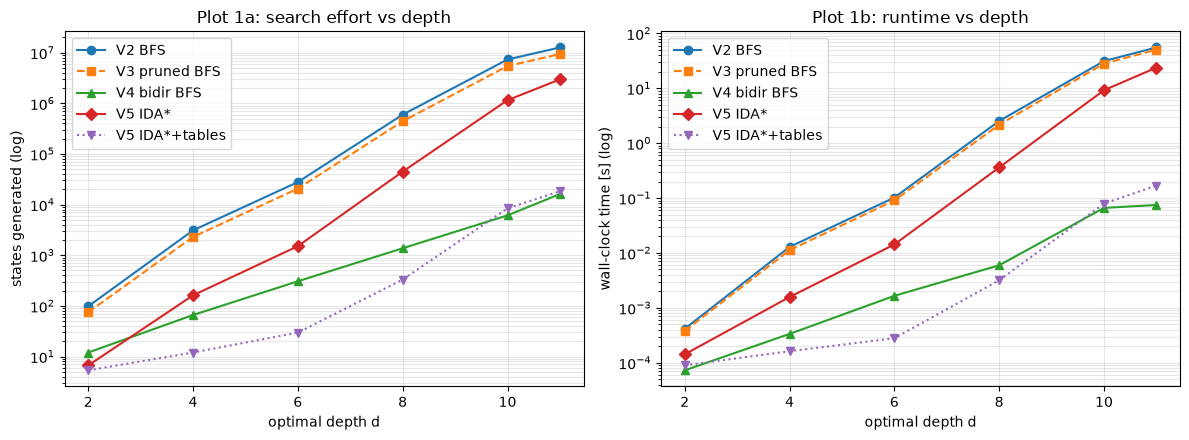

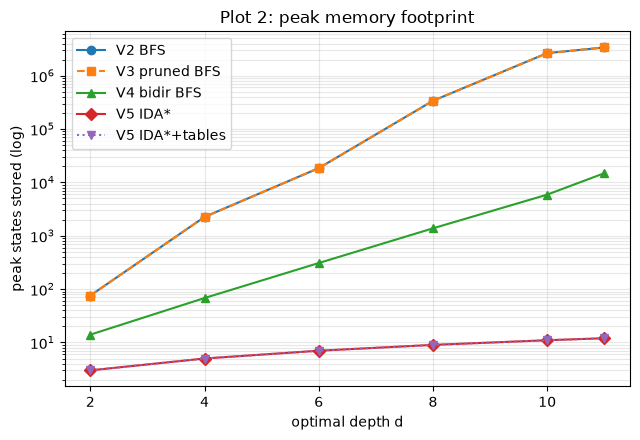

In [ ]:
import matplotlib.pyplot as plt
styles = {"V2 BFS": "o-", "V3 pruned BFS": "s--", "V4 bidir BFS": "^-", "V5 IDA*": "D-", "V5 IDA*+tables": "v:"}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name in SOLVERS:
    ax[0].plot(DEPTHS, [results[name][d][1] for d in DEPTHS], styles[name], label=name)
    ax[1].plot(DEPTHS, [max(results[name][d][3], 1e-5) for d in DEPTHS], styles[name], label=name)
ax[0].set(yscale="log", xlabel="optimal depth d", ylabel="states generated (log)", title="Plot 1a: search effort vs depth")
ax[1].set(yscale="log", xlabel="optimal depth d", ylabel="wall-clock time [s] (log)", title="Plot 1b: runtime vs depth")
for a in ax: a.grid(alpha=.3, which="both"); a.legend()
plt.tight_layout(); plt.savefig("plot1_effort_time.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name in SOLVERS:
    ax.plot(DEPTHS, [results[name][d][2] for d in DEPTHS], styles[name], label=name)
ax.set(yscale="log", xlabel="optimal depth d", ylabel="peak states stored (log)",
       title="Plot 2: peak memory footprint")
ax.grid(alpha=.3, which="both"); ax.legend()
plt.tight_layout(); plt.savefig("plot2_memory.png", dpi=150); plt.show()

In [ ]:
# Effective branching factor between consecutive measured depths: (effort(d2)/effort(d1))^(1/(d2-d1))
print("effective branching factor (states generated)")
for name in SOLVERS:
    bf = []
    for d1, d2 in zip(DEPTHS, DEPTHS[1:]):
        g1, g2 = results[name][d1][1], results[name][d2][1]
        bf.append(f"{(g2 / g1) ** (1 / (d2 - d1)):.2f}")
    print(f"{name:15s}", bf)

effective branching factor (states generated)
V2 BFS          ['5.62', '3.00', '4.63', '3.51', '1.73']
V3 pruned BFS   ['5.55', '3.00', '4.63', '3.51', '1.73']
V4 bidir BFS    ['2.35', '2.15', '2.12', '2.11', '2.64']
V5 IDA*         ['4.92', '3.06', '5.45', '5.07', '2.57']
V5 IDA*+tables  ['1.50', '1.57', '3.34', '5.05', '2.17']


## Summary (Part C Q6)

| Stage | Data structures in RAM | Time to find a depth-d solution | Peak memory | Shortest path guaranteed? |
|---|---|---|---|---|
| V1 sticker DFS | 24-element mutable list per frame, recursion stack | O(6^D) for cap D ≥ d (infinite with no cap) | O(D) frames | No |
| V2 BFS | FIFO deque + hash map of tuples | O(6^d), capped by O(\|V\|·6) | O(6^d) states | Yes |
| V3 pruned BFS | deque of (state, last moves) + hash map | O(b_eff^d), b_eff ≈ 4 | O(b_eff^d) | Yes |
| V4 bidirectional BFS | 2 deques + 2 hash maps | O(2·b_eff^(d/2)) | O(2·b_eff^(d/2)) | Yes |
| V5 IDA* | recursion stack (current path only) + heuristic (+ 729/5,040-entry tables) | O(b_eff^d) worst case, much less with a good h | O(d) | Yes (h admissible) |

**Observations from our runs** (mean of 3 states per depth; times under 1 ms are noisy):

| d = 11 | states generated | peak states stored | time |
|---|---|---|---|
| V2 BFS | 12,658,708 | 3,370,251 | 25.3 s |
| V3 pruned BFS | 9,397,398 | 3,370,251 | 30.6 s |
| V4 bidirectional BFS | 16,158 | 14,857 | 0.06 s |
| V5 IDA* (corner h) | 2,965,049 | 12 | 5.4 s |
| V5 IDA* + pattern tables | 18,332 | 12 | 0.04 s |

- **V2 → V3:** pruning generates about 26% fewer successors but expands exactly the same states (V2's hash map already blocks repeats). In Python the extra rule checks make V3 about 20% *slower*. Pruning pays off in tree searches without a visited set, i.e. Stage 5.
- **V3 → V4:** meet-in-the-middle cuts work by about 580× and memory by about 230× at d = 11. Its effective branching factor is about 2.1 per depth level, close to √4.6.
- **V4 → V5:** IDA* needs only d + 1 states in memory (12 at d = 11, against 3.37 million for V2). With the weak corner heuristic (h ≤ 2) it does about 180× more work than V4. The two small pattern tables (729 + 5,040 entries) give the best overall result: fastest at d = 11 and O(d) memory.
- Every solver was checked against an exact distance table of all 3,674,160 states.
